In [2]:
import pandas as pd
import matplotlib.pyplot as plt

files = ["data/orders_2024_01.csv", "data/orders_2024_02.csv", "data/orders_2024_03.csv"]

df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
df["order_datetime"] = pd.to_datetime(df["order_datetime"])
df["revenue"] = df["price"] * df["quantity"]
df["order_date"] = df["order_datetime"].dt.date

daily = df.groupby("order_date")["revenue"].sum().to_frame("revenue_sum")
daily.index = pd.to_datetime(daily.index)
daily = daily.sort_index()

print(daily.head())

            revenue_sum
order_date             
2024-01-01   4483590.00
2024-01-02   4095217.58
2024-01-03   4425023.45
2024-01-04   3747060.38
2024-01-05   4623480.03


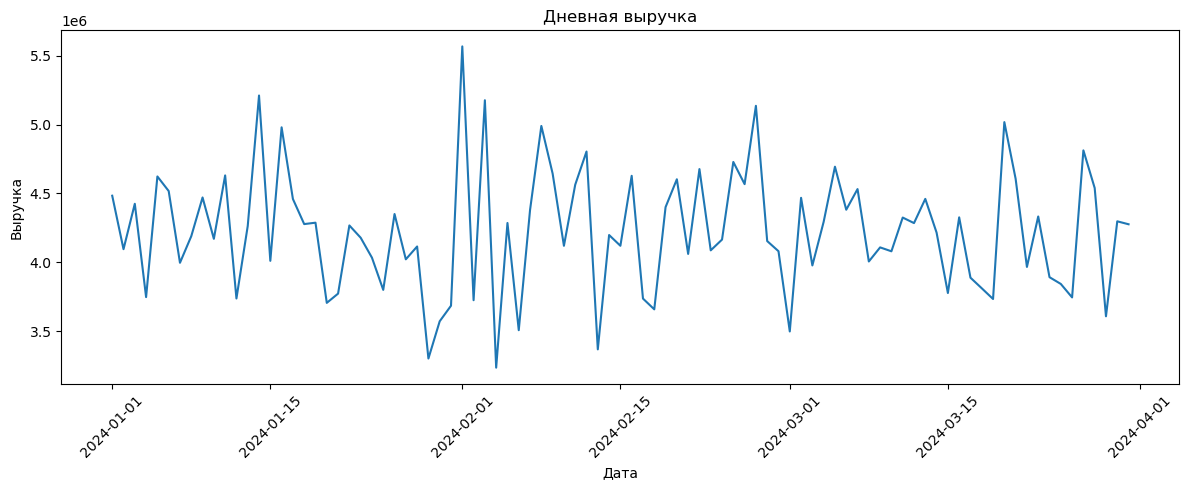

In [3]:
plt.figure(figsize=(12, 5))
plt.plot(daily.index, daily["revenue_sum"])
plt.title("Дневная выручка")
plt.xlabel("Дата")
plt.ylabel("Выручка")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [4]:
max_day = daily["revenue_sum"].idxmax()
print("День максимальной выручки:", max_day.date())
print("Сумма:", round(daily.loc[max_day, "revenue_sum"], 0))

День максимальной выручки: 2024-02-01
Сумма: 5568239.0


In [5]:
min_day = daily["revenue_sum"].idxmin()
print("День минимальной выручки:", min_day.date())
print("Сумма:", round(daily.loc[min_day, "revenue_sum"], 0))

День минимальной выручки: 2024-02-04
Сумма: 3234544.0
